# Student Performance Analysis & Prediction

**Goal:** analyse what drives student performance and predict each student's **final score** from information available *before* the final exam, so that students heading for trouble can be spotted early.

**Two outputs:**
1. A predicted final score (regression).
2. A practical "at risk" flag — predicted score below the 50% pass mark.

**Contents:** 1. Data → 2. Cleaning → 3. Exploratory analysis → 4. Modelling → 5. Evaluation → 6. What drives the score → 7. Early-warning use → 8. Limitations

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')

## 1. The dataset

`student_performance.csv` — 662 rows, 13 columns, one row per student.

The data is **simulated**, generated by `make_dataset.py`, which is included with this project. It is not collected from real students, so there are no privacy concerns, and the true relationships are known — useful for checking that the modelling recovers them. The generator deliberately adds missing values, duplicate rows, inconsistent category spellings and impossible values so that the cleaning step is real work.

| Column | Meaning |
|---|---|
| student_id | identifier |
| gender | Male / Female |
| study_hours_per_week | self-reported study time |
| attendance_percent | classes attended |
| previous_grade | last term's result (%) |
| assignments_submitted | out of 10 |
| absences | days absent |
| sleep_hours | average per night |
| tutoring, internet_access, extracurricular | Yes / No |
| parental_education | NoSchooling → Master |
| **final_score** | **target** — final exam result (%) |

In [2]:
df = pd.read_csv('student_performance.csv')
print(df.shape)
df.head()

(662, 13)


,student_id,gender,study_hours_per_week,attendance_percent,previous_grade,assignments_submitted,absences,sleep_hours,tutoring,internet_access,extracurricular,parental_education,final_score
0,S1306,Male,19.3,89.1,44.5,9,5,NaN,No,Yes,No,Secondary,75.4
1,S1155,Female,17.5,86.2,52.2,6,4,4.6,Yes,No,Yes,Secondary,62.9
2,S1047,Female,11.2,67.2,98.4,9,6,NaN,No,Yes,Yes,Secondary,100.0
3,S1111,Female,7.6,71.0,80.8,4,6,6.1,No,Yes,Yes,Secondary,47.7
4,S1245,Male,5.8,100.0,70.5,10,1,6.3,No,Yes,Yes,Primary,61.1


In [3]:
df.info()
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 662 entries, 0 to 661
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             662 non-null    str    
 1   gender                 662 non-null    str    
 2   study_hours_per_week   623 non-null    float64
 3   attendance_percent     637 non-null    float64
 4   previous_grade         662 non-null    float64
 5   assignments_submitted  662 non-null    int64  
 6   absences               662 non-null    int64  
 7   sleep_hours            632 non-null    float64
 8   tutoring               662 non-null    str    
 9   internet_access        662 non-null    str    
 10  extracurricular        662 non-null    str    
 11  parental_education     643 non-null    str    
 12  final_score            662 non-null    float64
dtypes: float64(5), int64(2), str(6)
memory usage: 67.4 KB


,study_hours_per_week,attendance_percent,previous_grade,assignments_submitted,absences,sleep_hours,final_score
count,623.00,637.00,662.00,662.00,662.00,632.00,662.00
mean,11.79,82.07,63.69,5.05,5.84,6.77,61.26
std,5.24,13.26,13.62,3.21,2.50,1.19,12.78
min,-5.00,46.50,22.30,0.00,0.00,3.20,14.60
25%,8.50,73.90,54.30,2.00,4.00,6.00,52.42
50%,12.10,82.00,64.70,5.00,6.00,6.70,61.55
75%,15.20,90.00,72.70,8.00,7.00,7.50,69.30
max,27.90,150.00,100.00,10.00,16.00,10.80,100.00


## 2. Data cleaning

Five problems to fix, in order:

1. **Duplicate rows** — exact repeats, dropped.
2. **Inconsistent categories** — `yes`, `YES`, `Yes` are the same answer; normalised.
3. **Impossible values** — attendance of 150% and negative study hours cannot be real, so they are set to missing and imputed with everything else.
4. **Missing values** — imputed later *inside the pipeline* (median / most frequent), so the training data alone decides the fill values.
5. **Identifier** — `student_id` is dropped; it carries no information about performance.

In [4]:
print('Rows before:', len(df))
df = df.drop_duplicates()
print('Rows after dropping duplicates:', len(df))

Rows before: 662
Rows after dropping duplicates: 650


In [5]:
for col in ['tutoring', 'internet_access', 'extracurricular', 'gender']:
    df[col] = df[col].str.strip().str.capitalize()
    print(col, '->', df[col].unique())

tutoring -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
internet_access -> <StringArray>
['Yes', 'No']
Length: 2, dtype: str
extracurricular -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
gender -> <StringArray>
['Male', 'Female']
Length: 2, dtype: str


In [6]:
bad_attendance = (df['attendance_percent'] > 100) | (df['attendance_percent'] < 0)
bad_study = df['study_hours_per_week'] < 0
print('Impossible attendance values:', bad_attendance.sum())
print('Negative study hours:', bad_study.sum())

df.loc[bad_attendance, 'attendance_percent'] = np.nan
df.loc[bad_study, 'study_hours_per_week'] = np.nan

Impossible attendance values: 6
Negative study hours: 4


In [7]:
missing = df.isna().sum()
print('Missing values left (filled inside the pipeline):')
print(missing[missing > 0])
print('\nCleaned shape:', df.shape)

Missing values left (filled inside the pipeline):
study_hours_per_week    42
attendance_percent      31
sleep_hours             30
parental_education      18
dtype: int64

Cleaned shape: (650, 13)


## 3. Exploratory analysis

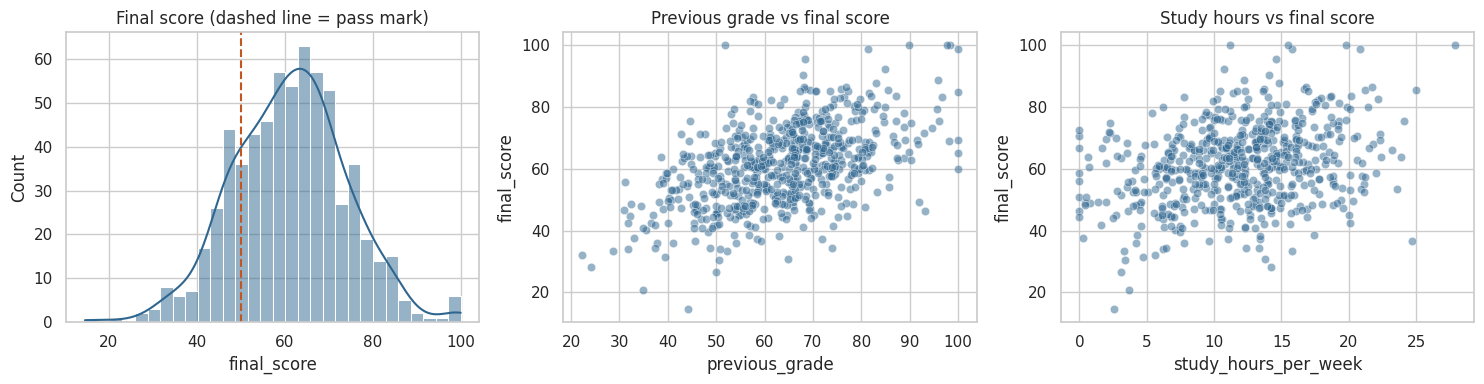

Share of students below the 50% pass mark: 0.195


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['final_score'], bins=30, kde=True, ax=axes[0], color='#2F6690')
axes[0].axvline(50, color='#C2561E', linestyle='--'); axes[0].set_title('Final score (dashed line = pass mark)')
sns.scatterplot(data=df, x='previous_grade', y='final_score', ax=axes[1], alpha=0.5, color='#2F6690')
axes[1].set_title('Previous grade vs final score')
sns.scatterplot(data=df, x='study_hours_per_week', y='final_score', ax=axes[2], alpha=0.5, color='#2F6690')
axes[2].set_title('Study hours vs final score')
plt.tight_layout(); plt.savefig('fig_distributions.png', dpi=150); plt.show()

print('Share of students below the 50% pass mark:',
      round((df['final_score'] < 50).mean(), 3))

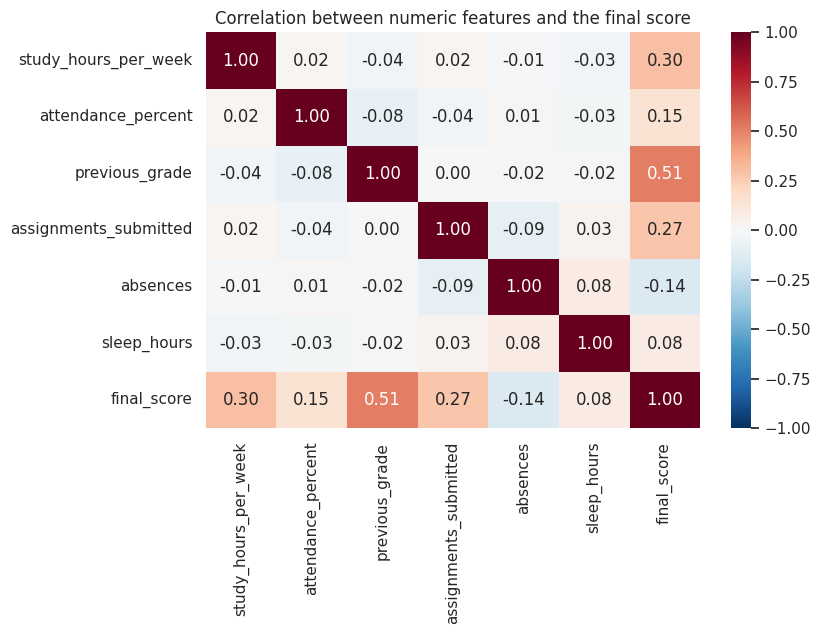

previous_grade           0.512
study_hours_per_week     0.298
assignments_submitted    0.274
attendance_percent       0.147
sleep_hours              0.081
absences                -0.145
Name: final_score, dtype: float64


In [9]:
num_cols = ['study_hours_per_week', 'attendance_percent', 'previous_grade',
            'assignments_submitted', 'absences', 'sleep_hours', 'final_score']
corr = df[num_cols].corr()
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlation between numeric features and the final score')
plt.tight_layout(); plt.savefig('fig_correlation.png', dpi=150); plt.show()
print(corr['final_score'].drop('final_score').sort_values(ascending=False).round(3))

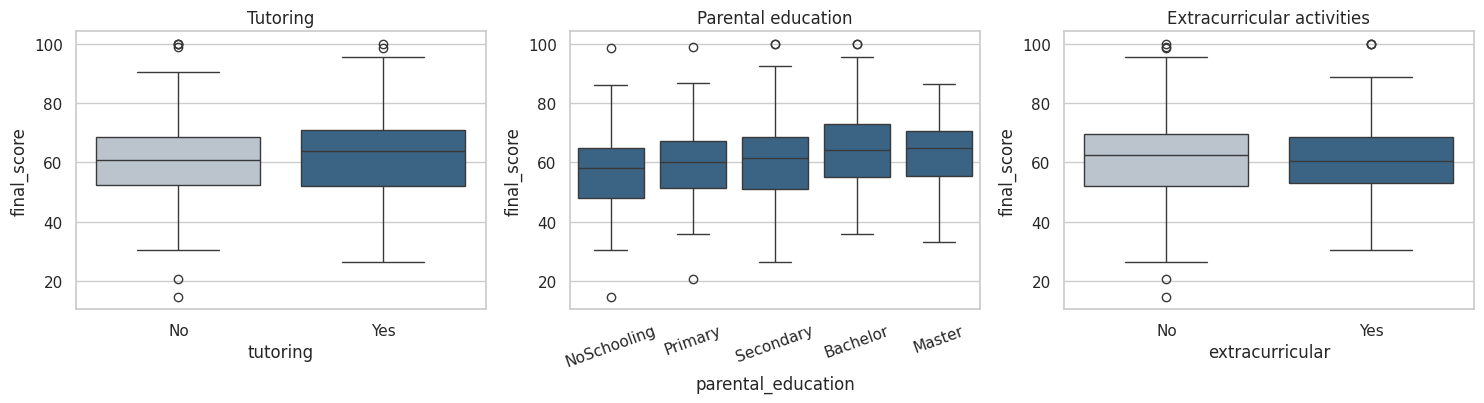

           mean  count
tutoring              
No        60.80    468
Yes       62.36    182


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.boxplot(data=df, x='tutoring', y='final_score', ax=axes[0], hue='tutoring', legend=False, palette=['#B8C4D0', '#2F6690'])
axes[0].set_title('Tutoring')
order = ['NoSchooling', 'Primary', 'Secondary', 'Bachelor', 'Master']
sns.boxplot(data=df, x='parental_education', y='final_score', order=order, ax=axes[1], color='#2F6690')
axes[1].set_title('Parental education'); axes[1].tick_params(axis='x', rotation=20)
sns.boxplot(data=df, x='extracurricular', y='final_score', ax=axes[2], hue='extracurricular', legend=False, palette=['#B8C4D0', '#2F6690'])
axes[2].set_title('Extracurricular activities')
plt.tight_layout(); plt.savefig('fig_groups.png', dpi=150); plt.show()

print(df.groupby('tutoring')['final_score'].agg(['mean', 'count']).round(2))

## 4. Modelling

- **Target:** `final_score` (continuous) → regression.
- **Features:** everything except `student_id` and the target.
- **Split:** 80 / 20, `random_state=42` for reproducibility.
- **Two models:** Linear Regression as the transparent baseline, Random Forest to catch any curves or interactions the line would miss.
- All preprocessing sits inside the pipeline, so imputation and scaling learn only from the training rows.
- Predictions are clipped to 0–100, since a score outside that range is not a possible result.

In [11]:
TARGET = 'final_score'
X = df.drop(columns=['student_id', TARGET])
y = df[TARGET]

NUM_COLS = X.select_dtypes(include=np.number).columns.tolist()
CAT_COLS = X.select_dtypes(exclude=np.number).columns.tolist()
print('Numeric:', NUM_COLS)
print('Categorical:', CAT_COLS)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)

preprocessor = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), NUM_COLS),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), CAT_COLS),
])

Numeric: ['study_hours_per_week', 'attendance_percent', 'previous_grade', 'assignments_submitted', 'absences', 'sleep_hours']
Categorical: ['gender', 'tutoring', 'internet_access', 'extracurricular', 'parental_education']
Train: (520, 11)  Test: (130, 11)


In [12]:
models = {
    'Linear Regression': Pipeline([('prep', preprocessor), ('model', LinearRegression())]),
    'Random Forest': Pipeline([('prep', preprocessor),
                               ('model', RandomForestRegressor(n_estimators=300, max_depth=12,
                                                               min_samples_leaf=3,
                                                               random_state=RANDOM_STATE))]),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print('Trained:', name)

Trained: Linear Regression


Trained: Random Forest


## 5. Evaluation

Three metrics, because each says something different:

- **MAE** — average error in percentage points. The easiest to explain to a teacher.
- **RMSE** — like MAE but punishes large misses; compare with MAE to see whether errors are evenly spread.
- **R²** — the share of the variation in scores the model explains. 0 = no better than always predicting the average.

In [13]:
rows, preds = [], {}
for name, m in models.items():
    p = np.clip(m.predict(X_test), 0, 100); preds[name] = p
    rows.append({'Model': name,
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'R2': r2_score(y_test, p)})
results = pd.DataFrame(rows).set_index('Model').round(3)
results.to_csv('metrics.csv')
results

,MAE,RMSE,R2
Model,,,
Linear Regression,6.688,8.124,0.559
Random Forest,7.027,8.759,0.487


In [14]:
baseline = np.full(len(y_test), y_train.mean())
print('Baseline (always predict the training mean):')
print('  MAE :', round(mean_absolute_error(y_test, baseline), 2))
print('  RMSE:', round(np.sqrt(mean_squared_error(y_test, baseline)), 2))
print('  R2  :', round(r2_score(y_test, baseline), 3))

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring='r2')
    cv_rows.append({'Model': name, 'CV R2 mean': s.mean(), 'CV R2 std': s.std()})
cv_results = pd.DataFrame(cv_rows).set_index('Model').round(3)
cv_results.to_csv('cv.csv')
cv_results

Baseline (always predict the training mean):
  MAE : 9.59
  RMSE: 12.25
  R2  : -0.003


,CV R2 mean,CV R2 std
Model,,
Linear Regression,0.481,0.091
Random Forest,0.416,0.055


Selected model: Linear Regression


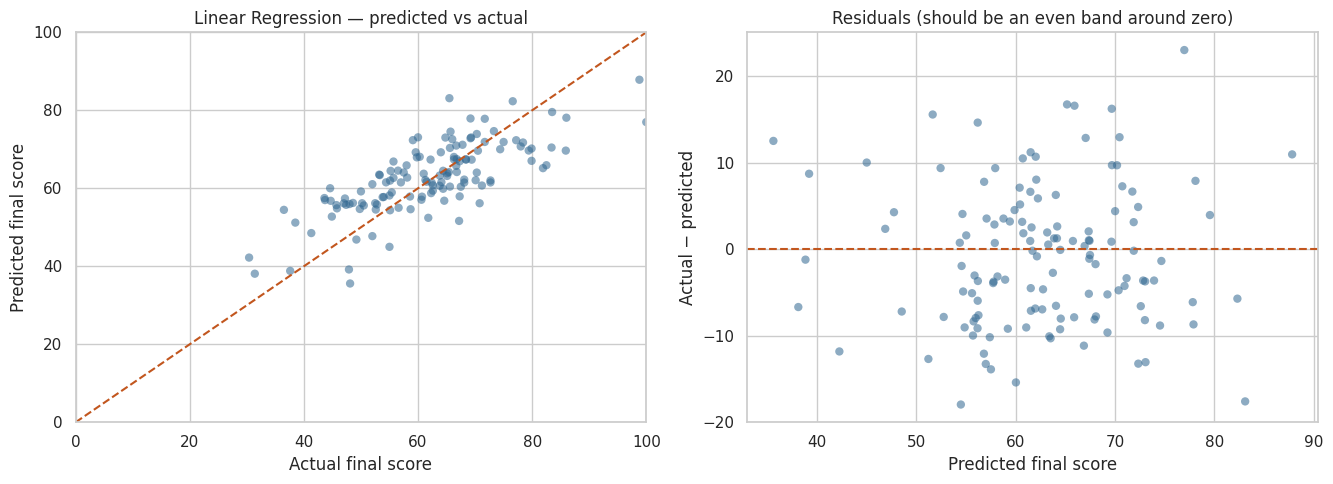

Residual mean: -0.84  std: 8.11


In [15]:
best = results['MAE'].idxmin()
final_model = models[best]
print('Selected model:', best)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
axes[0].scatter(y_test, preds[best], alpha=0.55, color='#2F6690', edgecolor='none')
lims = [0, 100]
axes[0].plot(lims, lims, color='#C2561E', linestyle='--')
axes[0].set_xlabel('Actual final score'); axes[0].set_ylabel('Predicted final score')
axes[0].set_title(f'{best} — predicted vs actual'); axes[0].set_xlim(lims); axes[0].set_ylim(lims)

residuals = y_test - preds[best]
axes[1].scatter(preds[best], residuals, alpha=0.55, color='#2F6690', edgecolor='none')
axes[1].axhline(0, color='#C2561E', linestyle='--')
axes[1].set_xlabel('Predicted final score'); axes[1].set_ylabel('Actual − predicted')
axes[1].set_title('Residuals (should be an even band around zero)')
plt.tight_layout(); plt.savefig('fig_predictions.png', dpi=150); plt.show()

print('Residual mean:', round(residuals.mean(), 2), ' std:', round(residuals.std(), 2))

## 6. What drives the score?

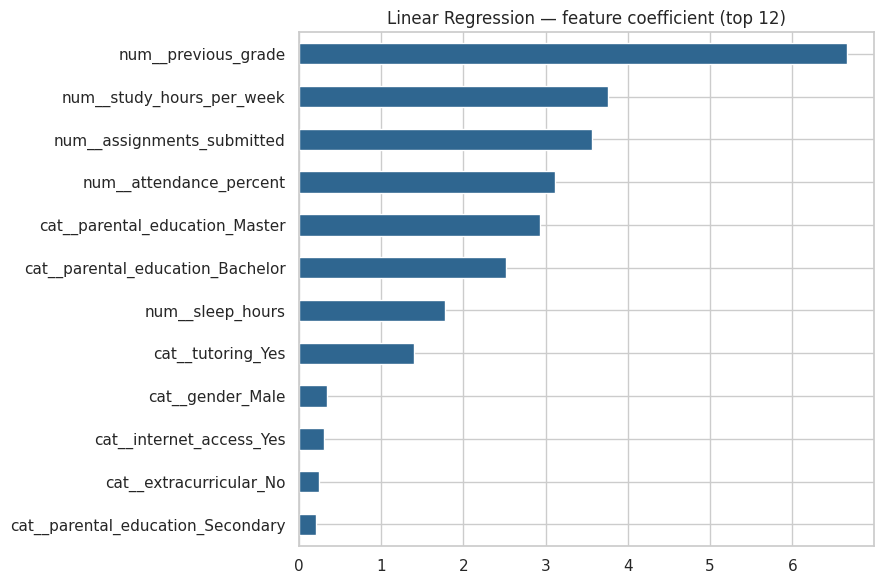

num__previous_grade                 6.659
num__study_hours_per_week           3.763
num__assignments_submitted          3.560
num__attendance_percent             3.117
cat__parental_education_Master      2.935
cat__parental_education_Bachelor    2.523
num__sleep_hours                    1.773
cat__tutoring_Yes                   1.406
dtype: float64


In [16]:
feat_names = final_model.named_steps['prep'].get_feature_names_out()
model_step = final_model.named_steps['model']
if hasattr(model_step, 'feature_importances_'):
    imp = pd.Series(model_step.feature_importances_, index=feat_names).sort_values()
    label = 'importance'
else:
    imp = pd.Series(model_step.coef_, index=feat_names).sort_values()
    label = 'coefficient'

plt.figure(figsize=(9, 6))
imp.tail(12).plot(kind='barh', color='#2F6690')
plt.title(f'{best} — feature {label} (top 12)')
plt.tight_layout(); plt.savefig('fig_importance.png', dpi=150); plt.show()
print(imp.sort_values(ascending=False).head(8).round(3))

## 7. Turning predictions into an early warning

A predicted number on its own does not help a teacher act. Converting it into a flag does: **predicted score below 50 → at risk**.

This is what the model would be used for in practice, so it is worth measuring how well the flag works — especially **recall**, because missing a struggling student is worse than checking on one who turns out fine.

Students actually below 50: 22 of 130
Flagged by the model      : 9

Precision: 0.778
Recall   : 0.318
F1       : 0.452


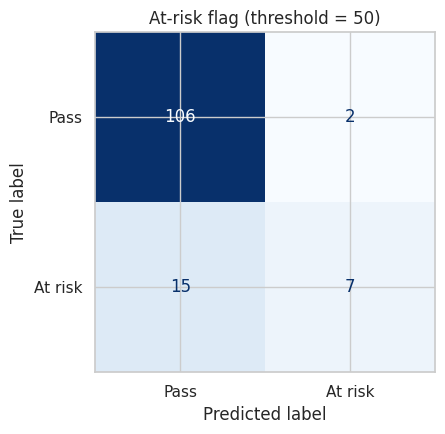

In [17]:
at_risk_actual = (y_test < 50).astype(int)
at_risk_pred = (preds[best] < 50).astype(int)

print('Students actually below 50:', at_risk_actual.sum(), 'of', len(y_test))
print('Flagged by the model      :', at_risk_pred.sum())
print()
print('Precision:', round(precision_score(at_risk_actual, at_risk_pred, zero_division=0), 3))
print('Recall   :', round(recall_score(at_risk_actual, at_risk_pred, zero_division=0), 3))
print('F1       :', round(f1_score(at_risk_actual, at_risk_pred, zero_division=0), 3))

cm = confusion_matrix(at_risk_actual, at_risk_pred)
pd.DataFrame(cm, index=['Actually passed', 'Actually below 50'],
             columns=['Not flagged', 'Flagged']).to_csv('at_risk.csv')

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=['Pass', 'At risk']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('At-risk flag (threshold = 50)')
plt.tight_layout(); plt.savefig('fig_at_risk.png', dpi=150); plt.show()

In [18]:
# A higher cut-off catches more of the struggling students, at the cost of more false alarms.
rows = []
for t in [50, 55, 60, 65]:
    flag = (preds[best] < t).astype(int)
    rows.append({'Threshold': t,
                 'Flagged': int(flag.sum()),
                 'Precision': precision_score(at_risk_actual, flag, zero_division=0),
                 'Recall': recall_score(at_risk_actual, flag, zero_division=0)})
thresholds = pd.DataFrame(rows).set_index('Threshold').round(3)
thresholds.to_csv('thresholds.csv')
thresholds

,Flagged,Precision,Recall
Threshold,,,
50,9,0.778,0.318
55,19,0.632,0.545
60,47,0.447,0.955
65,81,0.272,1.000


## 8. Predicting for new students

In [19]:
def predict_student(model=final_model, **kwargs):
    """Predict a final score and an at-risk flag for one student."""
    row = pd.DataFrame([{c: kwargs.get(c, np.nan) for c in X.columns}])
    score = float(np.clip(model.predict(row), 0, 100)[0])
    return round(score, 1), 'AT RISK' if score < 50 else 'On track'

examples = [
    dict(gender='Female', study_hours_per_week=20, attendance_percent=95, previous_grade=78,
         assignments_submitted=10, absences=1, sleep_hours=7.5, tutoring='Yes',
         internet_access='Yes', extracurricular='No', parental_education='Bachelor'),
    dict(gender='Male', study_hours_per_week=4, attendance_percent=58, previous_grade=45,
         assignments_submitted=3, absences=18, sleep_hours=5.5, tutoring='No',
         internet_access='No', extracurricular='Yes', parental_education='Primary'),
    dict(gender='Male', study_hours_per_week=12, attendance_percent=80, previous_grade=62,
         assignments_submitted=7, absences=5, sleep_hours=np.nan, tutoring='No',
         internet_access='Yes', extracurricular='No', parental_education='Secondary'),
]
out = pd.DataFrame(examples)
out[['Predicted score', 'Status']] = [predict_student(**e) for e in examples]
out[['study_hours_per_week', 'attendance_percent', 'previous_grade', 'absences',
     'tutoring', 'Predicted score', 'Status']].to_csv('examples.csv', index=False)
out[['study_hours_per_week', 'attendance_percent', 'previous_grade', 'absences',
     'tutoring', 'Predicted score', 'Status']]

,study_hours_per_week,attendance_percent,previous_grade,absences,tutoring,Predicted score,Status
0,20,95,78,1,Yes,91.9,On track
1,4,58,45,18,No,26.1,AT RISK
2,12,80,62,5,No,62.6,On track


## 9. Limitations

- **The data is simulated.** Relationships were written into the generator, so the model recovering them proves the pipeline works — not that these effects hold for real students. Every number here should be re-measured on real data before it is believed.
- **Correlation is not cause.** Tutoring correlates with higher scores; that does not mean assigning tutoring raises them. Students who seek tutoring may differ in ways the data does not record.
- **Self-reported inputs.** Study hours and sleep are the kind of fields students over-report. Errors in the inputs become errors in the prediction.
- **Missing context.** Nothing here captures teaching quality, subject difficulty, health, work commitments or family circumstances — all of which matter.
- **An error of a few points is still an error.** Around the 50-point line, a small miss flips a student from "fine" to "at risk" and back. The flag should start a conversation, never decide anything on its own.
- **Fairness.** `gender` and `parental_education` are in the model. Before real use, predictions must be checked for uneven error rates across those groups, and the school should consider dropping the features entirely.
- **A good R² is not deployment readiness.** No external validation, no monitoring for drift, and no check of what happens when staff act on the flags.